# Predicción de Recuperación de Oro

## Proyecto Sprint 13

Este notebook desarrolla un pipeline completo de machine learning para predecir la eficiencia de recuperación de oro en un proceso industrial de purificación.

El proyecto tiene tres restricciones centrales:

1. Los datos están indexados por tiempo, por lo que observaciones cercanas no son independientes.
2. El conjunto de prueba no contiene variables objetivo.
3. Varias columnas del conjunto de entrenamiento no están disponibles en test porque se miden o calculan más tarde en el proceso.

Por estas restricciones, el modelo debe evitar información futura y debe evaluarse con una estrategia de validación que respete el orden temporal.

## 1. Objetivo del Proyecto

El objetivo es predecir dos variables de recuperación:

- `rougher.output.recovery`
- `final.output.recovery`

La métrica final del proyecto es un sMAPE ponderado:

- 25% para la recuperación rougher
- 75% para la recuperación final

La recuperación final tiene mayor peso porque representa el resultado final del proceso de purificación.

## 2. Configuración

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import make_scorer, mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.float_format", "{:,.4f}".format)

RANDOM_STATE = 42

TARGETS = ["rougher.output.recovery", "final.output.recovery"]

FILE_CANDIDATES = {
    "train": ["gold_recovery_train.csv", "gold_recovery_train(2).csv"],
    "test": ["gold_recovery_test.csv", "gold_recovery_test(2).csv"],
    "full": ["gold_recovery_full.csv", "gold_recovery_full(2).csv"],
}

SEARCH_DIRS = [
    Path("/datasets"),
    Path("../data"),
    Path("data"),
    Path("."),
    Path("/mnt/data"),
]

## 3. Carga de Datos

Las instrucciones del proyecto mencionan el directorio `/data/`.  
Para que el notebook sea portable, el cargador busca los archivos en varias ubicaciones comunes:

- `/datasets`
- `../data`
- `data`
- directorio actual
- `/mnt/data`

Esto evita depender de una sola ruta local y conserva compatibilidad con la ruta oficial del proyecto.

In [2]:
def resolve_data_path(candidates, search_dirs=SEARCH_DIRS):
    """
    Encuentra la primera ruta existente entre varios nombres posibles y directorios de búsqueda.

    Parameters
    ----------
    candidates : list[str]
        Posibles nombres de archivo para el mismo dataset.
    search_dirs : list[pathlib.Path]
        Directorios donde pueden estar ubicados los archivos.

    Returns
    -------
    pathlib.Path
        Ruta existente para el archivo solicitado.

    Raises
    ------
    FileNotFoundError
        Si ninguno de los archivos candidatos existe en los directorios revisados.
    """
    checked_paths = []

    for directory in search_dirs:
        for filename in candidates:
            path = directory / filename
            checked_paths.append(str(path))
            if path.exists():
                return path

    raise FileNotFoundError(
        "No se encontró el archivo del dataset. Rutas revisadas:\n"
        + "\n".join(checked_paths)
    )


def load_gold_recovery_data(file_candidates=FILE_CANDIDATES):
    """
    Carga los tres datasets de recuperación de oro y convierte la columna date a formato datetime.

    Parameters
    ----------
    file_candidates : dict
        Mapeo entre nombres lógicos de datasets y posibles nombres de archivo.

    Returns
    -------
    dict[str, pandas.DataFrame]
        Diccionario con los datasets train, test y full.
    """
    datasets = {}

    for name, candidates in file_candidates.items():
        path = resolve_data_path(candidates)
        datasets[name] = pd.read_csv(path, parse_dates=["date"])
        print(f"{name}: {datasets[name].shape} cargado desde {path}")

    return datasets


datasets = load_gold_recovery_data()

train_raw = datasets["train"].copy()
test_raw = datasets["test"].copy()
full_raw = datasets["full"].copy()

train: (16860, 87) cargado desde ../data/gold_recovery_train(2).csv
test: (5856, 53) cargado desde ../data/gold_recovery_test(2).csv


full: (22716, 87) cargado desde ../data/gold_recovery_full(2).csv


## 4. Inspección Inicial de los Datos

Antes de modelar, se revisa:

- tamaño de cada dataset
- rango de fechas
- número de columnas
- valores ausentes
- fechas duplicadas

Esto permite confirmar si los conjuntos train, test y full son estructuralmente consistentes.

In [3]:
def summarize_dataset(name, df):
    """
    Construye un resumen estructural compacto de un dataset.

    Parameters
    ----------
    name : str
        Nombre del dataset.
    df : pandas.DataFrame
        Dataset a resumir.

    Returns
    -------
    dict
        Indicadores estructurales principales.
    """
    return {
        "dataset": name,
        "rows": df.shape[0],
        "columns": df.shape[1],
        "date_min": df["date"].min(),
        "date_max": df["date"].max(),
        "missing_values": int(df.isna().sum().sum()),
        "duplicated_dates": int(df["date"].duplicated().sum()),
    }


summary = pd.DataFrame(
    [
        summarize_dataset("train", train_raw),
        summarize_dataset("test", test_raw),
        summarize_dataset("full", full_raw),
    ]
)

display(summary)
display(train_raw.head())

,dataset,rows,columns,date_min,date_max,missing_values,duplicated_dates
0,train,16860,87,2016-01-15 00:00:00,2018-08-18 10:59:59,30320,0
1,test,5856,53,2016-09-01 00:59:59,2017-12-31 23:59:59,2360,0
2,full,22716,87,2016-01-15 00:00:00,2018-08-18 10:59:59,36587,0


,date,final.output.concentrate_ag,final.output.concentrate_pb,final.output.concentrate_sol,final.output.concentrate_au,final.output.recovery,final.output.tail_ag,final.output.tail_pb,final.output.tail_sol,final.output.tail_au,primary_cleaner.input.sulfate,primary_cleaner.input.depressant,primary_cleaner.input.feed_size,primary_cleaner.input.xanthate,primary_cleaner.output.concentrate_ag,primary_cleaner.output.concentrate_pb,primary_cleaner.output.concentrate_sol,primary_cleaner.output.concentrate_au,primary_cleaner.output.tail_ag,primary_cleaner.output.tail_pb,primary_cleaner.output.tail_sol,primary_cleaner.output.tail_au,primary_cleaner.state.floatbank8_a_air,primary_cleaner.state.floatbank8_a_level,primary_cleaner.state.floatbank8_b_air,primary_cleaner.state.floatbank8_b_level,primary_cleaner.state.floatbank8_c_air,primary_cleaner.state.floatbank8_c_level,primary_cleaner.state.floatbank8_d_air,primary_cleaner.state.floatbank8_d_level,rougher.calculation.sulfate_to_au_concentrate,rougher.calculation.floatbank10_sulfate_to_au_feed,rougher.calculation.floatbank11_sulfate_to_au_feed,rougher.calculation.au_pb_ratio,rougher.input.feed_ag,rougher.input.feed_pb,rougher.input.feed_rate,rougher.input.feed_size,rougher.input.feed_sol,rougher.input.feed_au,rougher.input.floatbank10_sulfate,rougher.input.floatbank10_xanthate,rougher.input.floatbank11_sulfate,rougher.input.floatbank11_xanthate,rougher.output.concentrate_ag,rougher.output.concentrate_pb,rougher.output.concentrate_sol,rougher.output.concentrate_au,rougher.output.recovery,rougher.output.tail_ag,rougher.output.tail_pb,rougher.output.tail_sol,rougher.output.tail_au,rougher.state.floatbank10_a_air,rougher.state.floatbank10_a_level,rougher.state.floatbank10_b_air,rougher.state.floatbank10_b_level,rougher.state.floatbank10_c_air,rougher.state.floatbank10_c_level,rougher.state.floatbank10_d_air,rougher.state.floatbank10_d_level,rougher.state.floatbank10_e_air,rougher.state.floatbank10_e_level,rougher.state.floatbank10_f_air,rougher.state.floatbank10_f_level,secondary_cleaner.output.tail_ag,secondary_cleaner.output.tail_pb,secondary_cleaner.output.tail_sol,secondary_cleaner.output.tail_au,secondary_cleaner.state.floatbank2_a_air,secondary_cleaner.state.floatbank2_a_level,secondary_cleaner.state.floatbank2_b_air,secondary_cleaner.state.floatbank2_b_level,secondary_cleaner.state.floatbank3_a_air,secondary_cleaner.state.floatbank3_a_level,secondary_cleaner.state.floatbank3_b_air,secondary_cleaner.state.floatbank3_b_level,secondary_cleaner.state.floatbank4_a_air,secondary_cleaner.state.floatbank4_a_level,secondary_cleaner.state.floatbank4_b_air,secondary_cleaner.state.floatbank4_b_level,secondary_cleaner.state.floatbank5_a_air,secondary_cleaner.state.floatbank5_a_level,secondary_cleaner.state.floatbank5_b_air,secondary_cleaner.state.floatbank5_b_level,secondary_cleaner.state.floatbank6_a_air,secondary_cleaner.state.floatbank6_a_level
0,2016-01-15 00:00:00,6.0554,9.8896,5.5073,42.1920,70.5412,10.4120,0.8954,16.9043,2.1431,127.0920,10.1283,7.2500,0.9888,8.5476,10.3896,19.5293,34.1744,14.9365,2.5349,7.4761,2.1067,"1,549.7758",-498.9121,"1,551.4342",-516.4034,"1,549.8739",-498.6666,"1,554.3674",-493.4281,"41,885.7070","3,481.7791","3,520.3372",2.8387,6.1004,2.2849,523.5463,55.4866,36.8086,6.4861,11.9866,6.0080,11.8367,6.0058,11.5008,7.1011,28.0293,19.7938,87.1078,5.0080,0.5087,19.1543,1.1702,999.7069,-404.0670,"1,603.0114",-434.7150,"1,602.3750",-442.2045,"1,598.9373",-451.2941,"1,404.4720",-455.4630,"1,416.3550",-451.9396,14.5002,4.6948,8.7646,2.6062,25.8531,-498.5265,23.8937,-501.4063,23.9618,-495.2628,21.9404,-499.3410,14.0168,-502.4880,12.0999,-504.7159,9.9256,-498.3102,8.0797,-500.4710,14.1513,-605.8420
1,2016-01-15 01:00:00,6.0294,9.9689,5.2578,42.7016,69.2662,10.4627,0.9275,16.6345,2.2249,125.6292,10.2963,7.2500,1.0027,8.5587,10.4971,19.3691,34.1185,16.2505,3.0496,6.7339,2.3530,"1,576.1667",-500.9050,"1,575.9506",-499.8659,"1,575.9942",-499.3151,"1,574.4793",-498.9317,"42,050.8618",

### Hallazgos de la inspección inicial

Los datasets de entrenamiento y fuente completa contienen la información completa del proceso, mientras que el conjunto de prueba contiene menos columnas. Esto es esperado porque test excluye las variables objetivo y variables que solo se conocen después de etapas posteriores del proceso.

La columna `date` es esencial: permite recuperar los objetivos del conjunto de prueba desde el dataset completo para evaluación local, y también define el orden temporal correcto para la validación.

## 5. Validación de la Fórmula de Recuperación

El proyecto pide comprobar si `rougher.output.recovery` fue calculada correctamente.

La fórmula de recuperación es:

$
Recovery = \frac{C(F - T)}{F(C - T)} \times 100
$

Donde:

- \(F\) = `rougher.input.feed_au`
- \(C\) = `rougher.output.concentrate_au`
- \(T\) = `rougher.output.tail_au`

Calculamos la recuperación manualmente y la comparamos contra el objetivo entregado usando EAM / MAE.

In [4]:
def calculate_recovery(feed, concentrate, tail):
    """
    Calcula el porcentaje de recuperación usando las concentraciones de alimentación, concentrado y colas.

    Parameters
    ----------
    feed : pandas.Series
        Concentración de alimentación.
    concentrate : pandas.Series
        Concentración de concentrado.
    tail : pandas.Series
        Concentración de colas.

    Returns
    -------
    pandas.Series
        Porcentaje de recuperación calculado.
    """
    denominator = feed * (concentrate - tail)
    recovery = concentrate * (feed - tail) / denominator * 100
    return recovery.replace([np.inf, -np.inf], np.nan)


calculated_recovery = calculate_recovery(
    feed=train_raw["rougher.input.feed_au"],
    concentrate=train_raw["rougher.output.concentrate_au"],
    tail=train_raw["rougher.output.tail_au"],
)

valid_recovery_mask = (
    calculated_recovery.notna()
    & train_raw["rougher.output.recovery"].notna()
)

recovery_mae = mean_absolute_error(
    train_raw.loc[valid_recovery_mask, "rougher.output.recovery"],
    calculated_recovery.loc[valid_recovery_mask],
)

print(f"EAM / MAE entre recuperación calculada y entregada: {recovery_mae:.12f}")

EAM / MAE entre recuperación calculada y entregada: 0.000000000000


### Hallazgo sobre la validación de recuperación

El EAM / MAE es prácticamente cero. Esto confirma que el objetivo `rougher.output.recovery` es consistente con la fórmula oficial.

Este control es importante: si el objetivo estuviera mal calculado, la evaluación del modelo sería poco confiable desde el inicio.

## 6. Variables No Disponibles en el Conjunto de Prueba

El conjunto de prueba contiene menos columnas porque algunos parámetros se miden o calculan después del momento de predicción. Estas columnas no pueden usarse como variables del modelo.

Usarlas generaría fuga de información: el modelo aprendería a partir de información que no estaría disponible al momento de hacer predicciones reales.

In [5]:
def infer_process_stage(column_name):
    """
    Infere la etapa del proceso a partir del nombre de una variable.

    Parameters
    ----------
    column_name : str
        Nombre de columna del dataset.

    Returns
    -------
    str
        Etapa del proceso en formato legible.
    """
    if column_name.startswith("rougher."):
        return "rougher"
    if column_name.startswith("primary_cleaner."):
        return "primary_cleaner"
    if column_name.startswith("secondary_cleaner."):
        return "secondary_cleaner"
    if column_name.startswith("final."):
        return "final"
    return "other"


def infer_parameter_type(column_name):
    """
    Infere el tipo de parámetro a partir del nombre de una variable.

    Parameters
    ----------
    column_name : str
        Nombre de columna del dataset.

    Returns
    -------
    str
        Categoría del parámetro, como input, output, state o calculation.
    """
    parts = column_name.split(".")
    return parts[1] if len(parts) > 1 else "unknown"


missing_in_test = sorted(set(train_raw.columns) - set(test_raw.columns))

missing_features_table = pd.DataFrame(
    {
        "feature": missing_in_test,
        "dtype": [str(train_raw[col].dtype) for col in missing_in_test],
        "stage": [infer_process_stage(col) for col in missing_in_test],
        "parameter_type": [infer_parameter_type(col) for col in missing_in_test],
    }
)

print(f"Número de columnas presentes en train pero ausentes en test: {len(missing_features_table)}")
display(missing_features_table.head(20))
display(missing_features_table["parameter_type"].value_counts().to_frame("count"))
display(missing_features_table["stage"].value_counts().to_frame("count"))

Número de columnas presentes en train pero ausentes en test: 34


,feature,dtype,stage,parameter_type
0,final.output.concentrate_ag,float64,final,output
1,final.output.concentrate_au,float64,final,output
2,final.output.concentrate_pb,float64,final,output
3,final.output.concentrate_sol,float64,final,output
4,final.output.recovery,float64,final,output
5,final.output.tail_ag,float64,final,output
6,final.output.tail_au,float64,final,output
7,final.output.tail_pb,float64,final,output
8,final.output.tail_sol,float64,final,output
9,primary_cleaner.output.concentrate_ag,float64,primary_cleaner,output


,count
parameter_type,
output,30
calculation,4


,count
stage,
rougher,13
final,9
primary_cleaner,8
secondary_cleaner,4


### Hallazgo sobre variables no disponibles

La mayoría de las columnas no disponibles son variables de salida o cálculo. Esto es esperado: se conocen solamente después de que la etapa del proceso ya ocurrió.

Para modelar, el conjunto seguro de variables debe ser la intersección entre train y test, excluyendo `date` y las variables objetivo.

## 7. Estrategia de Preprocesamiento

La estrategia de preprocesamiento respeta la estructura del proceso industrial:

1. Ordenar todos los datasets por `date`.
2. Recuperar los objetivos ocultos de test desde `full` usando `date`.
3. Usar solamente variables disponibles tanto en train como en test.
4. Eliminar filas de entrenamiento sin variable objetivo.
5. Manejar valores ausentes dentro de pipelines de sklearn mediante imputación por mediana.

La imputación por mediana se coloca dentro del pipeline de modelado para evitar duplicación de código y mantener limpia la validación cruzada.

In [6]:
train = train_raw.sort_values("date").reset_index(drop=True)
test = test_raw.sort_values("date").reset_index(drop=True)
full = full_raw.sort_values("date").reset_index(drop=True)

test_targets = test[["date"]].merge(
    full[["date"] + TARGETS],
    on="date",
    how="left",
)

print("Valores objetivo faltantes recuperados para test:")
display(test_targets[TARGETS].isna().sum().to_frame("missing_count"))

safe_features = sorted((set(train.columns) & set(test.columns)) - {"date"} - set(TARGETS))

print(f"Número de variables seguras para modelado: {len(safe_features)}")
print("Primeras 10 variables seguras:")
print(safe_features[:10])

Valores objetivo faltantes recuperados para test:


,missing_count
rougher.output.recovery,546
final.output.recovery,442


Número de variables seguras para modelado: 52
Primeras 10 variables seguras:
['primary_cleaner.input.depressant', 'primary_cleaner.input.feed_size', 'primary_cleaner.input.sulfate', 'primary_cleaner.input.xanthate', 'primary_cleaner.state.floatbank8_a_air', 'primary_cleaner.state.floatbank8_a_level', 'primary_cleaner.state.floatbank8_b_air', 'primary_cleaner.state.floatbank8_b_level', 'primary_cleaner.state.floatbank8_c_air', 'primary_cleaner.state.floatbank8_c_level']


## 8. Análisis Exploratorio de Datos

### 8.1 Concentraciones de Metales por Etapa de Purificación

Se analiza cómo cambian las concentraciones de Au, Ag y Pb a través de las etapas del proceso.

El comportamiento esperado es que la concentración de oro aumente conforme avanza la purificación. Otros metales pueden comportarse de forma distinta dependiendo de cómo cada etapa separa el material.

metal,Ag,Au,Pb
stage,,,
feed,8.0657,7.5658,3.3057
final_concentrate,4.7816,40.0012,9.0953
rougher_concentrate,10.8745,17.8795,6.9006


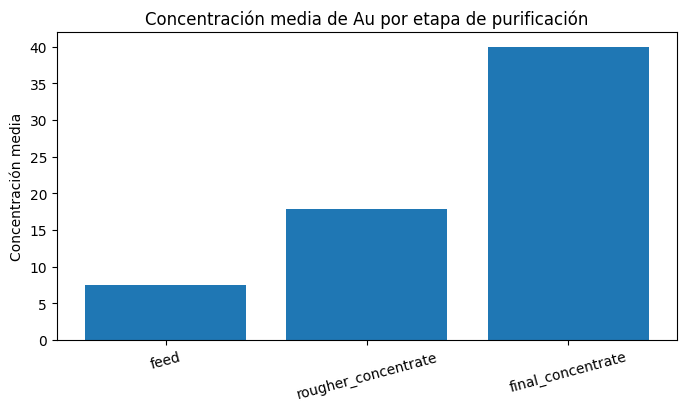

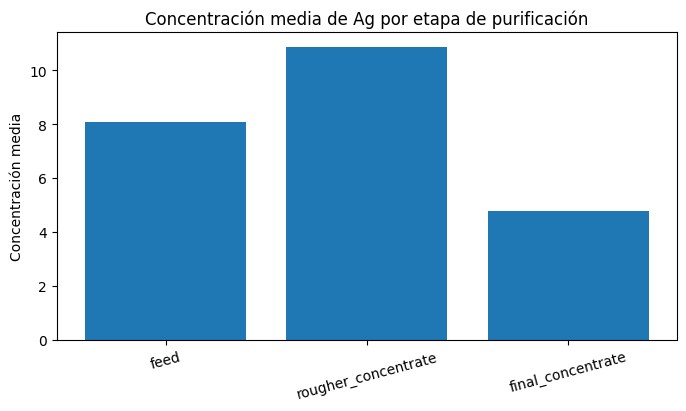

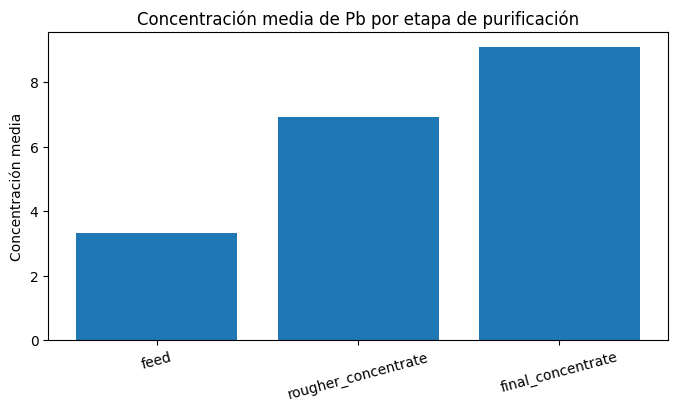

In [7]:
metal_stage_columns = {
    "feed": {
        "Au": "rougher.input.feed_au",
        "Ag": "rougher.input.feed_ag",
        "Pb": "rougher.input.feed_pb",
    },
    "rougher_concentrate": {
        "Au": "rougher.output.concentrate_au",
        "Ag": "rougher.output.concentrate_ag",
        "Pb": "rougher.output.concentrate_pb",
    },
    "final_concentrate": {
        "Au": "final.output.concentrate_au",
        "Ag": "final.output.concentrate_ag",
        "Pb": "final.output.concentrate_pb",
    },
}

metal_means = []

for stage, metal_columns in metal_stage_columns.items():
    for metal, column in metal_columns.items():
        metal_means.append(
            {
                "stage": stage,
                "metal": metal,
                "mean_concentration": full[column].mean(),
            }
        )

metal_means = pd.DataFrame(metal_means)

display(metal_means.pivot(index="stage", columns="metal", values="mean_concentration"))

for metal in ["Au", "Ag", "Pb"]:
    subset = metal_means[metal_means["metal"] == metal]
    plt.figure(figsize=(8, 4))
    plt.bar(subset["stage"], subset["mean_concentration"])
    plt.title(f"Concentración media de {metal} por etapa de purificación")
    plt.ylabel("Concentración media")
    plt.xticks(rotation=15)
    plt.show()

### Hallazgo sobre concentración de metales

La concentración de oro aumenta claramente desde la materia prima al concentrado rougher y luego al concentrado final. Esto confirma que el proceso de purificación funciona en la dirección esperada.

La plata y el plomo no necesariamente siguen el mismo patrón monotónico porque cada etapa está optimizada para recuperación de oro, no para maximizar la concentración de todos los metales.

### 8.2 Distribución del Tamaño de Partículas de Alimentación

El proyecto pide comparar las distribuciones del tamaño de partícula entre train y test.

Esto importa porque si la distribución del tamaño de alimentación cambia demasiado, el modelo podría evaluarse sobre una población distinta a la usada para entrenar.


Resumen de distribución: rougher.input.feed_size


,train,test,absolute_difference
count,"16,443.0000","5,834.0000","10,609.0000"
mean,58.6764,55.9375,2.7389
std,23.9226,22.7243,1.1983
min,9.6596,0.0464,9.6132
1%,28.3702,28.7235,0.3533
5%,36.3988,40.4863,4.0875
25%,47.5759,43.8909,3.6850
50%,54.1043,50.0020,4.1023
75%,65.0511,61.6384,3.4126
95%,85.1933,86.1169,0.9236


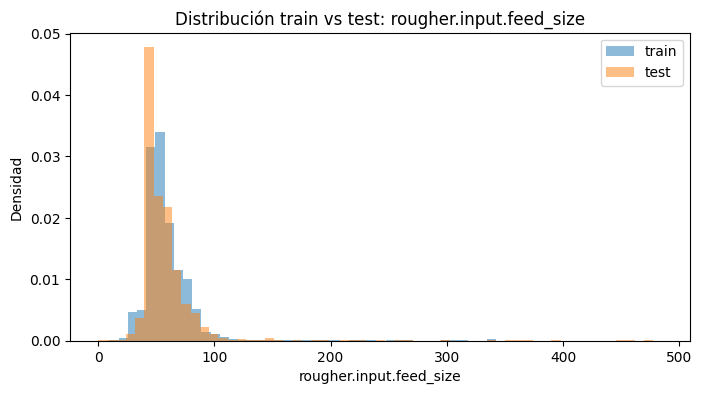


Resumen de distribución: primary_cleaner.input.feed_size


,train,test,absolute_difference
count,"16,860.0000","5,856.0000","11,004.0000"
mean,7.2973,7.2647,0.0326
std,0.6192,0.6115,0.0076
min,1.0800,5.6500,4.5700
1%,5.8500,5.8600,0.0100
5%,6.3232,6.3000,0.0232
25%,6.9400,6.8856,0.0544
50%,7.2850,7.2593,0.0257
75%,7.7000,7.6500,0.0500
95%,8.3400,8.2444,0.0956


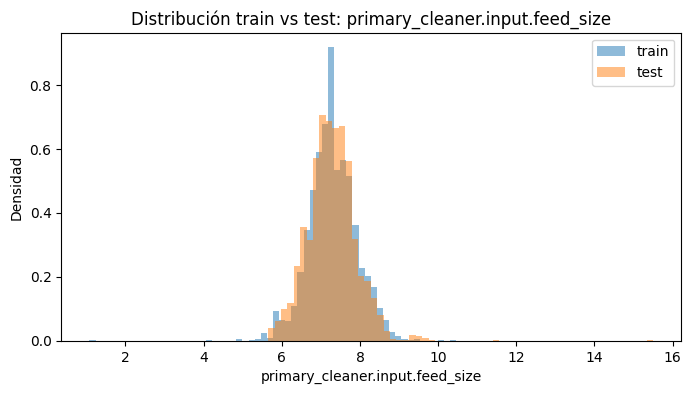

In [8]:
particle_size_columns = [
    "rougher.input.feed_size",
    "primary_cleaner.input.feed_size",
]

for column in particle_size_columns:
    if column in train.columns and column in test.columns:
        comparison = pd.DataFrame(
            {
                "train": train[column].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]),
                "test": test[column].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]),
            }
        )
        comparison["absolute_difference"] = (comparison["train"] - comparison["test"]).abs()

        print(f"\nResumen de distribución: {column}")
        display(comparison)

        plt.figure(figsize=(8, 4))
        plt.hist(train[column].dropna(), bins=60, alpha=0.5, density=True, label="train")
        plt.hist(test[column].dropna(), bins=60, alpha=0.5, density=True, label="test")
        plt.title(f"Distribución train vs test: {column}")
        plt.xlabel(column)
        plt.ylabel("Densidad")
        plt.legend()
        plt.show()

### Hallazgo sobre tamaño de partículas

Las distribuciones no son idénticas, pero sus rangos centrales se solapan lo suficiente como para continuar con la evaluación del modelo. Esto significa que test no es una copia perfecta de train, pero sí es suficientemente comparable para una evaluación razonable.

Esta revisión es importante porque un cambio fuerte de distribución haría menos confiable el resultado final.

### 8.3 Anomalías en Concentraciones Totales

El proyecto pide analizar la concentración total en tres etapas:

1. Materia prima
2. Concentrado rougher
3. Concentrado final

Las filas con concentración total cercana a cero son físicamente sospechosas: normalmente indican mediciones ausentes, corruptas o anómalas. Estas filas pueden distorsionar tanto el análisis exploratorio como el entrenamiento del modelo.

,total_concentration_raw_feed,total_concentration_rougher_concentrate,total_concentration_final_concentrate
count,"22,716.0000","22,716.0000","22,716.0000"
mean,51.5841,61.3781,62.1669
std,18.2500,23.5589,20.9541
min,0.0000,0.0000,0.0000
25%,51.2854,63.2632,67.0057
50%,56.7540,69.3997,69.2306
75%,61.4035,74.0156,71.1273
max,76.9789,90.9644,80.2106


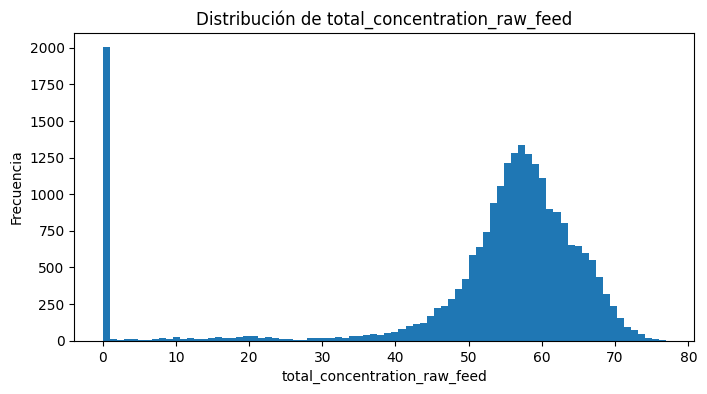

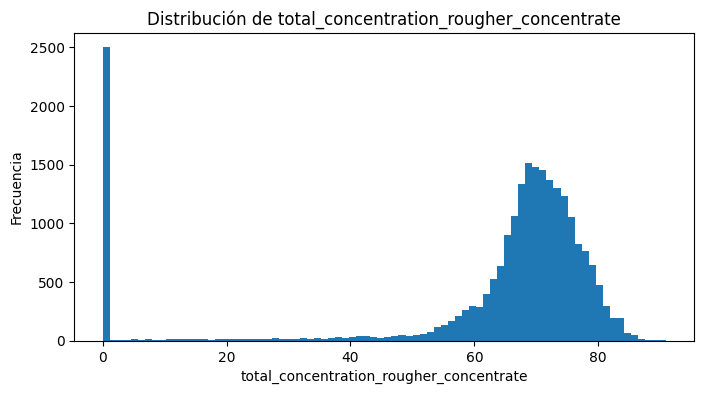

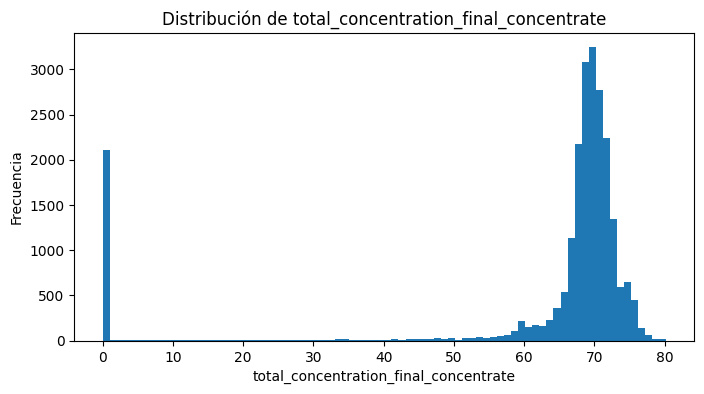

Fechas anómalas detectadas: 2846
Proporción del dataset full marcada como anómala: 12.53%


In [9]:
CONCENTRATION_STAGES = {
    "raw_feed": [
        "rougher.input.feed_ag",
        "rougher.input.feed_pb",
        "rougher.input.feed_sol",
        "rougher.input.feed_au",
    ],
    "rougher_concentrate": [
        "rougher.output.concentrate_ag",
        "rougher.output.concentrate_pb",
        "rougher.output.concentrate_sol",
        "rougher.output.concentrate_au",
    ],
    "final_concentrate": [
        "final.output.concentrate_ag",
        "final.output.concentrate_pb",
        "final.output.concentrate_sol",
        "final.output.concentrate_au",
    ],
}


def add_total_concentration_columns(df, stage_columns=CONCENTRATION_STAGES):
    """
    Agrega columnas de concentración total para las etapas seleccionadas.

    Parameters
    ----------
    df : pandas.DataFrame
        Dataset que contiene columnas de concentración.
    stage_columns : dict
        Mapeo entre etapas y columnas de concentración.

    Returns
    -------
    pandas.DataFrame
        Copia del dataset con columnas de concentración total agregadas.
    """
    df_with_totals = df.copy()

    for stage, columns in stage_columns.items():
        df_with_totals[f"total_concentration_{stage}"] = df_with_totals[columns].sum(axis=1)

    return df_with_totals


full_with_totals = add_total_concentration_columns(full)

total_columns = [f"total_concentration_{stage}" for stage in CONCENTRATION_STAGES]

display(full_with_totals[total_columns].describe())

for column in total_columns:
    plt.figure(figsize=(8, 4))
    plt.hist(full_with_totals[column].dropna(), bins=80)
    plt.title(f"Distribución de {column}")
    plt.xlabel(column)
    plt.ylabel("Frecuencia")
    plt.show()

ANOMALY_THRESHOLD = 1

anomaly_dates = set(
    full_with_totals.loc[
        (full_with_totals[total_columns] <= ANOMALY_THRESHOLD).any(axis=1),
        "date",
    ]
)

print(f"Fechas anómalas detectadas: {len(anomaly_dates)}")
print(f"Proporción del dataset full marcada como anómala: {len(anomaly_dates) / len(full_with_totals):.2%}")

### Decisión sobre anomalías

Se eliminan las filas con concentración total menor o igual a 1.

La detección de anomalías se realiza sobre el dataset fuente completo porque contiene todas las etapas de concentración. Después, las fechas anómalas se eliminan de forma consistente en train y test.

Esto mantiene las muestras de entrenamiento y evaluación alineadas bajo la misma regla de limpieza.

In [10]:
train_clean = train[~train["date"].isin(anomaly_dates)].copy()
test_clean = test[~test["date"].isin(anomaly_dates)].copy()
full_clean = full[~full["date"].isin(anomaly_dates)].copy()

rows_before_after = pd.DataFrame(
    {
        "dataset": ["train", "test", "full"],
        "rows_before": [len(train), len(test), len(full)],
        "rows_after": [len(train_clean), len(test_clean), len(full_clean)],
    }
)

rows_before_after["rows_removed"] = rows_before_after["rows_before"] - rows_before_after["rows_after"]
rows_before_after["removed_share"] = rows_before_after["rows_removed"] / rows_before_after["rows_before"]

display(rows_before_after)

,dataset,rows_before,rows_after,rows_removed,removed_share
0,train,16860,14594,2266,0.1344
1,test,5856,5276,580,0.0990
2,full,22716,19870,2846,0.1253


## 9. Construcción del Dataset de Modelado

El modelo utiliza solamente variables seguras: columnas presentes tanto en train como en test.

Los objetivos se toman de train para entrenamiento. Para evaluación local sobre test, los valores objetivo se recuperan desde el dataset full mediante `date`.

In [11]:
test_clean_targets = test_clean[["date"]].merge(
    full_clean[["date"] + TARGETS],
    on="date",
    how="left",
)

train_model = train_clean.dropna(subset=TARGETS).copy()
test_model = test_clean.reset_index(drop=True).copy()
test_clean_targets = test_clean_targets.reset_index(drop=True)

valid_test_target_mask = test_clean_targets[TARGETS].notna().all(axis=1)
test_model = test_model.loc[valid_test_target_mask].copy()
test_clean_targets = test_clean_targets.loc[valid_test_target_mask].copy()

X_train = train_model[safe_features].replace([np.inf, -np.inf], np.nan)
y_train = train_model[TARGETS]

X_test = test_model[safe_features].replace([np.inf, -np.inf], np.nan)
y_test = test_clean_targets[TARGETS]

print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (13789, 52)
y_train shape: (13789, 2)
X_test shape: (5154, 52)
y_test shape: (5154, 2)


## 10. Métrica de Evaluación: sMAPE

El proyecto usa sMAPE porque mide error relativo y depende menos de la escala que MAE.

$
sMAPE = \frac{1}{N}\sum_{i=1}^{N}\frac{|y_i-\hat{y}_i|}{(|y_i|+|\hat{y}_i|)/2} \times 100
$

La métrica final combina ambos objetivos:

$
Final\ sMAPE = 0.25 \times sMAPE(rougher) + 0.75 \times sMAPE(final)
$

In [12]:
def smape(y_true, y_pred):
    """
    Calcula el Error Porcentual Absoluto Medio Simétrico.

    Parameters
    ----------
    y_true : array-like
        Valores reales.
    y_pred : array-like
        Valores predichos.

    Returns
    -------
    float
        Valor sMAPE expresado como porcentaje.
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    denominator = (np.abs(y_true) + np.abs(y_pred)) / 2
    absolute_error = np.abs(y_true - y_pred)

    ratio = np.where(denominator == 0, 0, absolute_error / denominator)

    return np.mean(ratio) * 100


def final_smape(y_true, y_pred):
    """
    Calcula el sMAPE final ponderado para recuperación rougher y final.

    Parameters
    ----------
    y_true : array-like of shape (n_samples, 2)
        Valores reales para recuperación rougher y final.
    y_pred : array-like of shape (n_samples, 2)
        Valores predichos para recuperación rougher y final.

    Returns
    -------
    float
        sMAPE final ponderado.
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    rougher_score = smape(y_true[:, 0], y_pred[:, 0])
    final_score = smape(y_true[:, 1], y_pred[:, 1])

    return 0.25 * rougher_score + 0.75 * final_score


smape_scorer = make_scorer(final_smape, greater_is_better=False)

## 11. Entrenamiento y Validación Cruzada

Como los datos son temporales, la validación cruzada aleatoria no es adecuada. Mezclar observaciones permitiría entrenar con datos parecidos al futuro y validar sobre datos parecidos al pasado, generando resultados demasiado optimistas.

Se utiliza `TimeSeriesSplit`, que preserva el orden cronológico y produce una validación más realista.

In [13]:
models = {
    "DummyRegressor": Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("model", DummyRegressor(strategy="mean")),
        ]
    ),
    "LinearRegression": Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LinearRegression()),
        ]
    ),
    "Ridge": Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", Ridge(alpha=1.0)),
        ]
    ),
    "DecisionTree": Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            (
                "model",
                DecisionTreeRegressor(
                    max_depth=6,
                    min_samples_leaf=20,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    ),
    "RandomForest": Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            (
                "model",
                RandomForestRegressor(
                    n_estimators=40,
                    max_depth=8,
                    min_samples_leaf=10,
                    random_state=RANDOM_STATE,
                    n_jobs=-1,
                ),
            ),
        ]
    ),
}

cv = TimeSeriesSplit(n_splits=3)

cv_results = []

for model_name, model in models.items():
    scores = -cross_val_score(
        model,
        X_train,
        y_train,
        scoring=smape_scorer,
        cv=cv,
        n_jobs=None,
    )

    cv_results.append(
        {
            "model": model_name,
            "mean_cv_smape": scores.mean(),
            "std_cv_smape": scores.std(),
        }
    )

cv_results = (
    pd.DataFrame(cv_results)
    .sort_values("mean_cv_smape")
    .reset_index(drop=True)
)

display(cv_results)

,model,mean_cv_smape,std_cv_smape
0,RandomForest,9.5378,1.2851
1,DecisionTree,10.2061,0.7022
2,DummyRegressor,10.3191,0.6211
3,Ridge,11.9508,0.4454
4,LinearRegression,12.0083,0.4013


### Hallazgo de selección de modelo

El mejor modelo se selecciona con el menor sMAPE medio en validación cruzada.

El modelo dummy se incluye como línea base. Cualquier modelo útil debería superar esta línea base; de lo contrario, el pipeline no estaría aprendiendo patrones relevantes del proceso.

## 12. Evaluación Final en Test

El modelo seleccionado se entrena con la muestra de entrenamiento limpia y se evalúa sobre la muestra de prueba limpia.

Los objetivos del test se recuperan desde el dataset full únicamente para evaluación local. No se usan como variables predictoras.

In [14]:
best_model_name = cv_results.loc[0, "model"]
best_model = models[best_model_name]

best_model.fit(X_train, y_train)
test_predictions = best_model.predict(X_test)

test_rougher_smape = smape(y_test.iloc[:, 0], test_predictions[:, 0])
test_final_smape = smape(y_test.iloc[:, 1], test_predictions[:, 1])
test_weighted_smape = final_smape(y_test, test_predictions)

print(f"Mejor modelo: {best_model_name}")
print(f"sMAPE rougher en test: {test_rougher_smape:.4f}")
print(f"sMAPE final en test: {test_final_smape:.4f}")
print(f"sMAPE final ponderado en test: {test_weighted_smape:.4f}")

Mejor modelo: RandomForest
sMAPE rougher en test: 4.8008
sMAPE final en test: 8.2452
sMAPE final ponderado en test: 7.3841


## 13. Conclusiones Finales

Este proyecto produjo un pipeline completo de machine learning para predecir recuperación de oro.

Conclusiones principales:

1. El objetivo de recuperación rougher entregado es correcto.
2. Muchas columnas ausentes en test son parámetros de salida o cálculo, por lo que no deben utilizarse como variables predictoras.
3. La concentración de oro aumenta a lo largo del proceso de purificación, confirmando el comportamiento industrial esperado.
4. Las distribuciones de tamaño de partícula entre train y test no son idénticas, pero son suficientemente comparables.
5. Las filas con concentración total cercana a cero son anómalas y fueron eliminadas.
6. `TimeSeriesSplit` es la estrategia correcta de validación porque los datos tienen estructura temporal.
7. El modelo final seleccionado mejora la línea base dummy y se evalúa con la métrica ponderada sMAPE requerida.

La decisión metodológica más importante es evitar fuga de información: tanto la selección de variables como la estrategia de validación están diseñadas alrededor de lo que estaría disponible en el momento real de predicción.